In [2]:
from google.colab import files
from pathlib import Path
from IPython.display import display
import pandas as pd
import zipfile

print("Upload RouteRanker_Module2_Vapi.zip")
uploaded = files.upload()

archives = [
    Path(name) for name in uploaded
    if name.lower().endswith(".zip")
]

if len(archives) != 1:
    raise ValueError("Upload exactly one Module 2 results ZIP.")

PROJECT = Path("/content/RouteRanker_Module3")
INPUT = PROJECT / "input"
REPORTS = PROJECT / "reports"
CHARTS = PROJECT / "charts"

for folder in [INPUT, REPORTS, CHARTS]:
    folder.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(archives[0]) as archive:
    root = INPUT.resolve()

    for member in archive.infolist():
        target = (INPUT / member.filename).resolve()
        if target != root and root not in target.parents:
            raise ValueError("Unsafe file path in archive.")

    archive.extractall(INPUT)

def read_output(filename):
    matches = list(INPUT.rglob(filename))

    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one {filename}; found {len(matches)}. "
            "Upload the Module 2 results ZIP, not the raw GTFS ZIP."
        )

    return pd.read_csv(
        matches[0],
        dtype="string",
        keep_default_na=False,
        encoding="utf-8-sig"
    )

profiles = read_output("vapi_route_profiles.csv")
trip_features = read_output("vapi_trip_features.csv")
hourly = read_output("vapi_hourly_departures.csv")

print("\nROUTE PROFILES")
print("Rows and columns:", profiles.shape)
print("Columns:", profiles.columns.tolist())
print("Service dates:", profiles["service_date"].unique().tolist())
display(profiles.head())

print("\nTRIP FEATURES")
print("Rows:", len(trip_features))

print("\nHOURLY DEPARTURES")
display(hourly.head())

print("\nStep 1 completed.")

Upload RouteRanker_Module2_Vapi.zip


Saving RouteRanker_Module2_Vapi.zip to RouteRanker_Module2_Vapi.zip

ROUTE PROFILES
Rows and columns: (22, 21)
Columns: ['route_id', 'agency_id', 'route_short_name', 'route_long_name', 'route_type', 'scheduled_trip_count', 'distinct_stop_count', 'trips_with_valid_departure', 'first_departure_seconds', 'last_departure_seconds', 'median_scheduled_duration_minutes', 'departure_span_hours', 'first_departure_gtfs', 'last_departure_gtfs', 'trips_with_shape_distance', 'median_trip_shape_length_km', 'min_trip_shape_length_km', 'max_trip_shape_length_km', 'service_date', 'day_of_week', 'day_type']
Service dates: ['2026-10-31']


,route_id,agency_id,route_short_name,route_long_name,route_type,scheduled_trip_count,distinct_stop_count,trips_with_valid_departure,first_departure_seconds,last_departure_seconds,...,departure_span_hours,first_departure_gtfs,last_departure_gtfs,trips_with_shape_distance,median_trip_shape_length_km,min_trip_shape_length_km,max_trip_shape_length_km,service_date,day_of_week,day_type
0,1868,VCBS,11,"Vapi Town Post office - Meril, Welspun Company...",3,31,13,31,44820,76620,...,8.833333333333334,12:27:00,21:17:00,31,13.040083677456696,13.040083677456696,13.040083677456696,2026-10-31,Saturday,Weekend
1,1867,VCBS,10,"Vapi Town Post office - Dabhel Check Post, Kun...",3,16,4,16,46800,76500,...,8.25,13:00:00,21:15:00,16,2.884071923342277,2.884071923342277,2.884071923342277,2026-10-31,Saturday,Weekend
2,1829,VCBS,1,Vapi Railway Station (East) - G.I.D.C. Third P...,3,19,5,19,45540,70380,...,6.9,12:39:00,19:33:00,19,6.3543135055967745,6.3543135055967745,6.3543135055967745,2026-10-31,Saturday,Weekend
3,1890,VCBS,6,"Gunjan Intersection , Morarji Circle , Godal N...",3,9,7,9,46500,73380,...,7.466666666666667,12:55:00,20:23:00,9,8.280020023906218,8.280020023906218,8.280020023906218,2026-10-31,Saturday,Weekend
4,1833,VCBS,3,Vapi Railway Station (East) - Chhiri,3,21,5,21,43980,71580,...,7.666666666666667,12:13:00,19:53:00,21,10.607384267732343,10.607384267732343,10.607384267732343,2026-10-31,Saturday,Weekend



TRIP FEATURES
Rows: 461

HOURLY DEPARTURES


,route_id,service_hour,scheduled_departures,service_date
0,1829,12,2,2026-10-31
1,1829,13,2,2026-10-31
2,1829,14,3,2026-10-31
3,1829,15,3,2026-10-31
4,1829,16,2,2026-10-31



Step 1 completed.


Upload the Module 2 results ZIP.
Optionally select the original GTFS ZIP at the same time.


Saving RouteRanker_Module2_Vapi.zip to RouteRanker_Module2_Vapi (1).zip

DATASET SHAPE: (22, 21)
SERVICE DATE: 2026-10-31

DATA TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 21 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   route_id                           22 non-null     string 
 1   agency_id                          22 non-null     string 
 2   route_short_name                   22 non-null     string 
 3   route_long_name                    22 non-null     string 
 4   route_type                         22 non-null     string 
 5   scheduled_trip_count               22 non-null     Int64  
 6   distinct_stop_count                22 non-null     Int64  
 7   trips_with_valid_departure         22 non-null     Int64  
 8   first_departure_seconds            22 non-null     Int64  
 9   last_departure_seconds             22 non-null     Int

,route_id,agency_id,route_short_name,route_long_name,route_type,scheduled_trip_count,distinct_stop_count,trips_with_valid_departure,first_departure_seconds,last_departure_seconds,...,departure_span_hours,first_departure_gtfs,last_departure_gtfs,trips_with_shape_distance,median_trip_shape_length_km,min_trip_shape_length_km,max_trip_shape_length_km,service_date,day_of_week,day_type
0,1868,VCBS,11,"Vapi Town Post office - Meril, Welspun Company...",3,31,13,31,44820,76620,...,8.833333,12:27:00,21:17:00,31,13.040084,13.040084,13.040084,2026-10-31,Saturday,Weekend
1,1867,VCBS,10,"Vapi Town Post office - Dabhel Check Post, Kun...",3,16,4,16,46800,76500,...,8.25,13:00:00,21:15:00,16,2.884072,2.884072,2.884072,2026-10-31,Saturday,Weekend
2,1829,VCBS,1,Vapi Railway Station (East) - G.I.D.C. Third P...,3,19,5,19,45540,70380,...,6.9,12:39:00,19:33:00,19,6.354314,6.354314,6.354314,2026-10-31,Saturday,Weekend
3,1890,VCBS,6,"Gunjan Intersection , Morarji Circle , Godal N...",3,9,7,9,46500,73380,...,7.466667,12:55:00,20:23:00,9,8.28002,8.28002,8.28002,2026-10-31,Saturday,Weekend
4,1833,VCBS,3,Vapi Railway Station (East) - Chhiri,3,21,5,21,43980,71580,...,7.666667,12:13:00,19:53:00,21,10.607384,10.607384,10.607384,2026-10-31,Saturday,Weekend



LAST FIVE ROUTES


,route_id,agency_id,route_short_name,route_long_name,route_type,scheduled_trip_count,distinct_stop_count,trips_with_valid_departure,first_departure_seconds,last_departure_seconds,...,departure_span_hours,first_departure_gtfs,last_departure_gtfs,trips_with_shape_distance,median_trip_shape_length_km,min_trip_shape_length_km,max_trip_shape_length_km,service_date,day_of_week,day_type
17,1834,VCBS,3,Chhiri - Vapi Railway Station (East),3,21,5,21,45360,72960,...,7.666667,12:36:00,20:16:00,21,10.607384,10.607384,10.607384,2026-10-31,Saturday,Weekend
18,1843,VCBS,8,Railway Station (East) - Rata Khadi,3,9,3,9,44100,70980,...,7.466667,12:15:00,19:43:00,9,5.754098,5.754098,5.754098,2026-10-31,Saturday,Weekend
19,1844,VCBS,8,Rata Khadi - Railway Station (East),3,9,5,9,45780,72660,...,7.466667,12:43:00,20:11:00,9,5.354882,5.354882,5.354882,2026-10-31,Saturday,Weekend
20,1846,VCBS,9,Tambadi Fatak - Vapi Railway Station (East),3,27,4,27,45480,74460,...,8.05,12:38:00,20:41:00,27,1.971969,1.971969,1.971969,2026-10-31,Saturday,Weekend
21,1888,VCBS,12,"Shree mahalaxmi Mata mandir, Salvav - Vapi Rai...",3,9,5,9,47280,74160,...,7.466667,13:08:00,20:36:00,9,19.295992,19.295992,19.295992,2026-10-31,Saturday,Weekend



MISSING NUMERICAL VALUES AFTER VALIDATION


,0
scheduled_trip_count,0
distinct_stop_count,0
trips_with_valid_departure,0
first_departure_seconds,0
last_departure_seconds,0
median_scheduled_duration_minutes,0
departure_span_hours,0
trips_with_shape_distance,0
median_trip_shape_length_km,0
min_trip_shape_length_km,0



DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
scheduled_trip_count,22.0,20.954545,14.079628,9.0,9.0,20.0,26.75,62.0
distinct_stop_count,22.0,4.818182,2.4031,2.0,3.0,5.0,5.0,13.0
trips_with_valid_departure,22.0,20.954545,14.079628,9.0,9.0,20.0,26.75,62.0
first_departure_seconds,22.0,45264.545455,979.911207,43980.0,44340.0,45330.0,45600.0,47280.0
last_departure_seconds,22.0,73249.090909,1991.493599,70200.0,71820.0,72960.0,74415.0,76620.0
median_scheduled_duration_minutes,22.0,12.231061,9.430777,1.0,4.829167,9.158333,15.933333,29.283333
departure_span_hours,22.0,7.773485,0.588259,6.9,7.466667,7.566667,8.0375,8.966667
trips_with_shape_distance,22.0,20.954545,14.079628,9.0,9.0,20.0,26.75,62.0
median_trip_shape_length_km,22.0,7.108345,5.987106,0.196766,2.005953,6.054206,10.272029,22.080283
min_trip_shape_length_km,22.0,7.108345,5.987106,0.196766,2.005953,6.054206,10.272029,22.080283


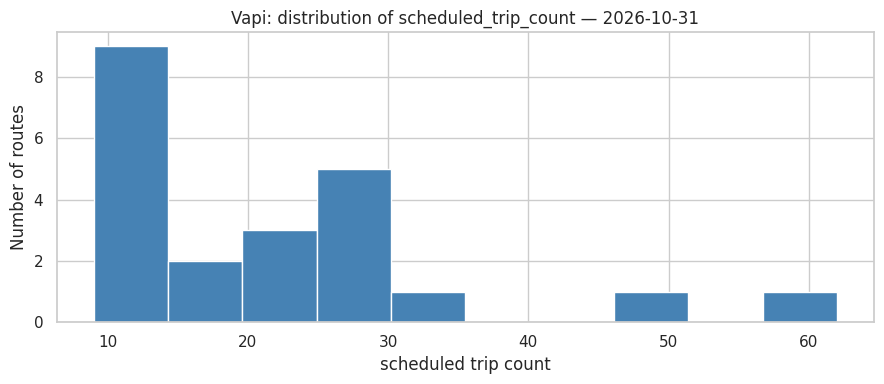

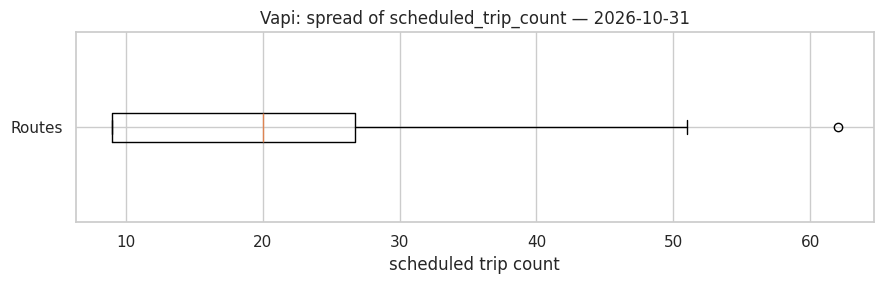

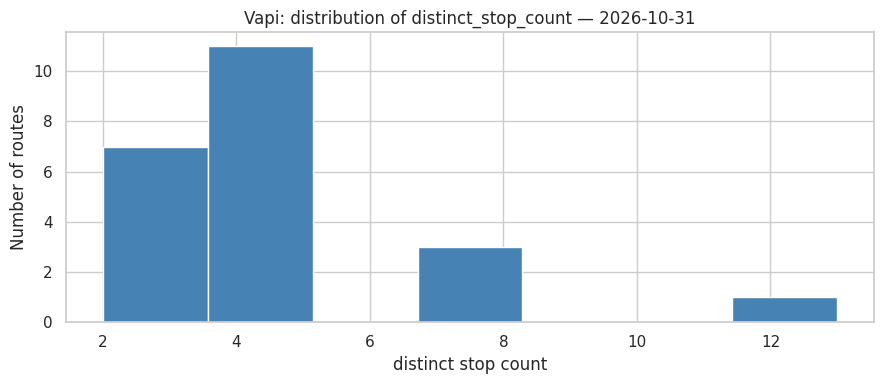

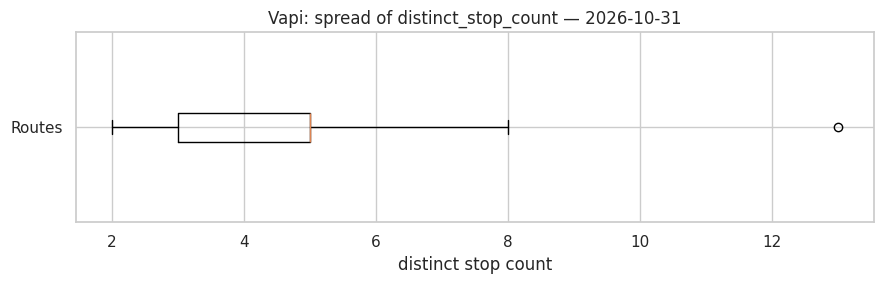

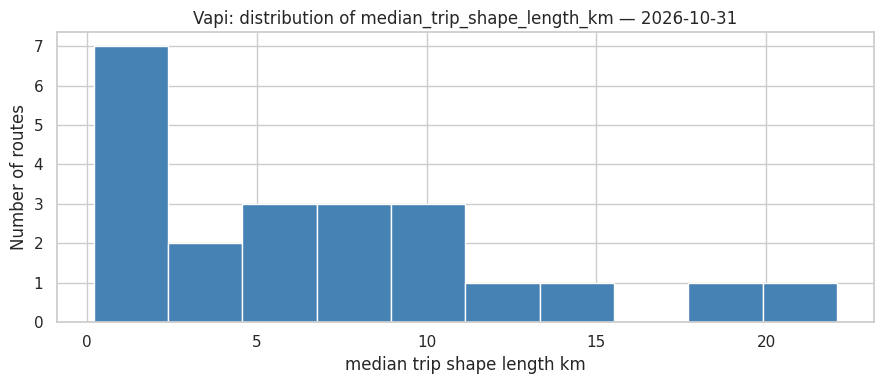

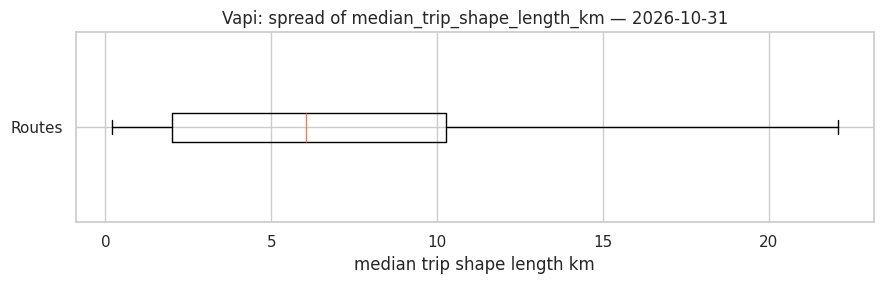

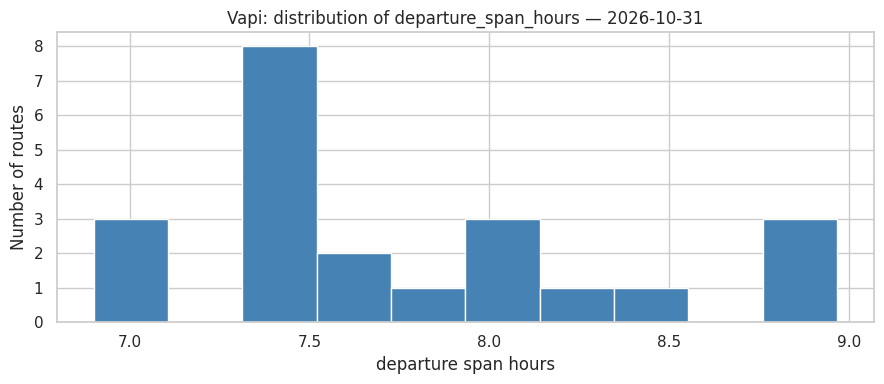

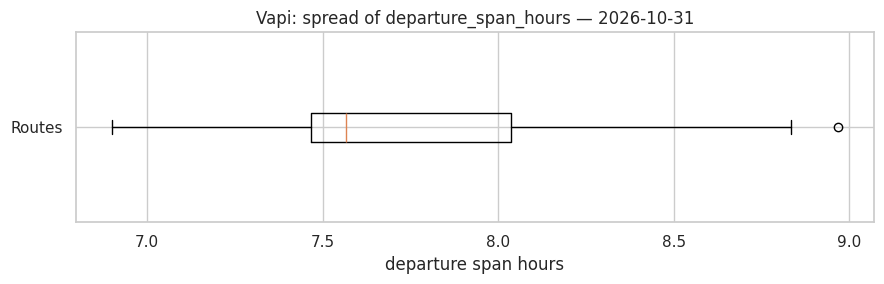

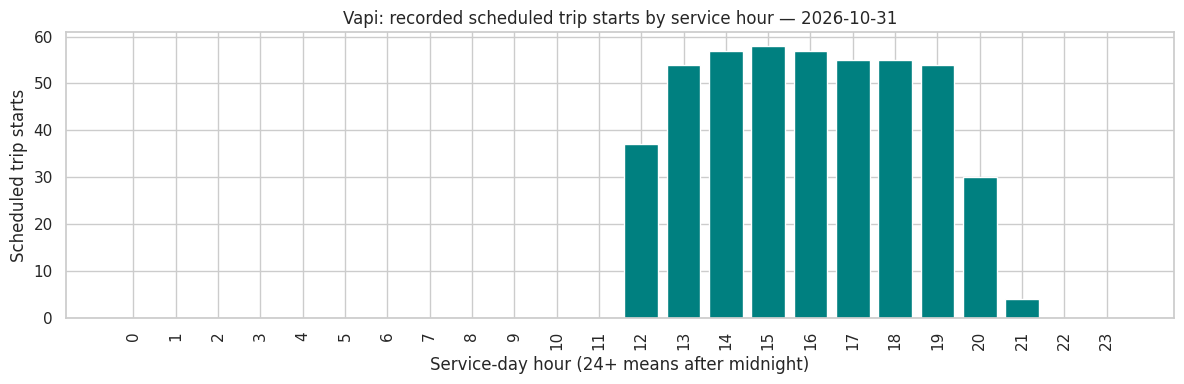

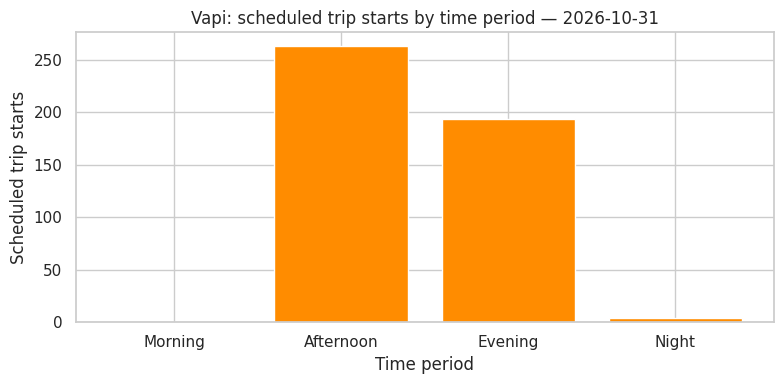


ROUTE COMPARISON


,route_id,agency_id,route_short_name,route_long_name,route_type,scheduled_trip_count,distinct_stop_count,trips_with_valid_departure,first_departure_seconds,last_departure_seconds,...,min_trip_shape_length_km,max_trip_shape_length_km,service_date,day_of_week,day_type,route_label,morning_trip_starts,afternoon_trip_starts,evening_trip_starts,night_trip_starts
11,1832,VCBS,2,Dadra check post - Vapi Railway Station (East),3,62,3,62,44160,74460,...,0.968608,0.968608,2026-10-31,Saturday,Weekend,ID 1832,0,36,26,0
5,1830,VCBS,1,G.I.D.C. Third Phase - Vapi Railway Station (E...,3,51,2,51,44160,72960,...,1.577181,1.577181,2026-10-31,Saturday,Weekend,ID 1830,0,30,21,0
0,1868,VCBS,11,"Vapi Town Post office - Meril, Welspun Company...",3,31,13,31,44820,76620,...,13.040084,13.040084,2026-10-31,Saturday,Weekend,ID 1868,0,16,14,1
14,1886,VCBS,7,Shubham Appartment (Bagwada Toll Plaza) - Vapi...,3,28,5,28,44220,75960,...,13.547364,13.547364,2026-10-31,Saturday,Weekend,ID 1886,0,14,13,1
20,1846,VCBS,9,Tambadi Fatak - Vapi Railway Station (East),3,27,4,27,45480,74460,...,1.971969,1.971969,2026-10-31,Saturday,Weekend,ID 1846,0,15,12,0
15,1885,VCBS,7,Vapi Railway Station (East) - Shubham Appartme...,3,27,3,27,45600,74280,...,9.265962,9.265962,2026-10-31,Saturday,Weekend,ID 1885,0,15,12,0
12,1879,VCBS,4,Vapi Railway Station(West) - Dabhel Check Post,3,26,3,26,44220,76500,...,1.542661,1.542661,2026-10-31,Saturday,Weekend,ID 1879,0,15,10,1
10,1845,VCBS,9,Vapi Railway Station (East) - Tambadi Fatak,3,26,4,26,44700,72780,...,1.971969,1.971969,2026-10-31,Saturday,Weekend,ID 1845,0,15,11,0
9,1831,VCBS,2,Vapi Railway Station (East) - Dadra check post,3,24,8,24,44820,70200,...,8.702078,8.702078,2026-10-31,Saturday,Weekend,ID 1831,0,15,9,0
4,1833,VCBS,3,Vapi Railway Station (East) - Chhiri,3,21,5,21,43980,71580,...,10.607384,10.607384,2026-10-31,Saturday,Weekend,ID 1833,0,13,8,0


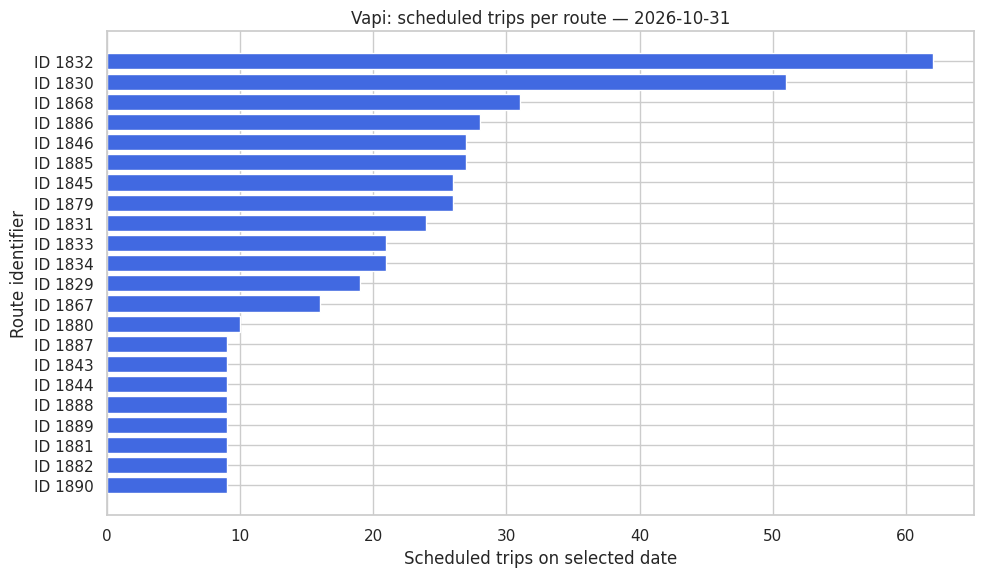

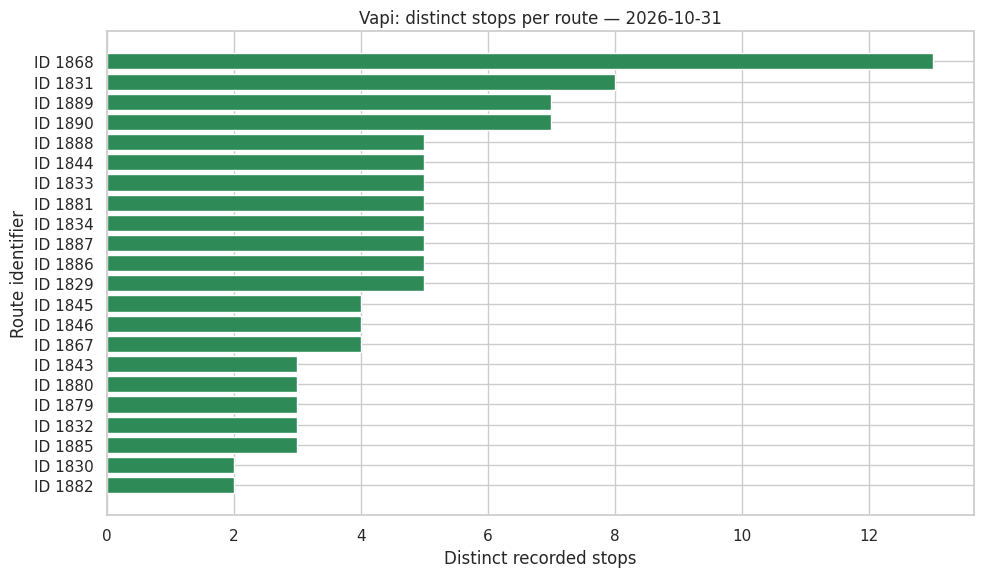

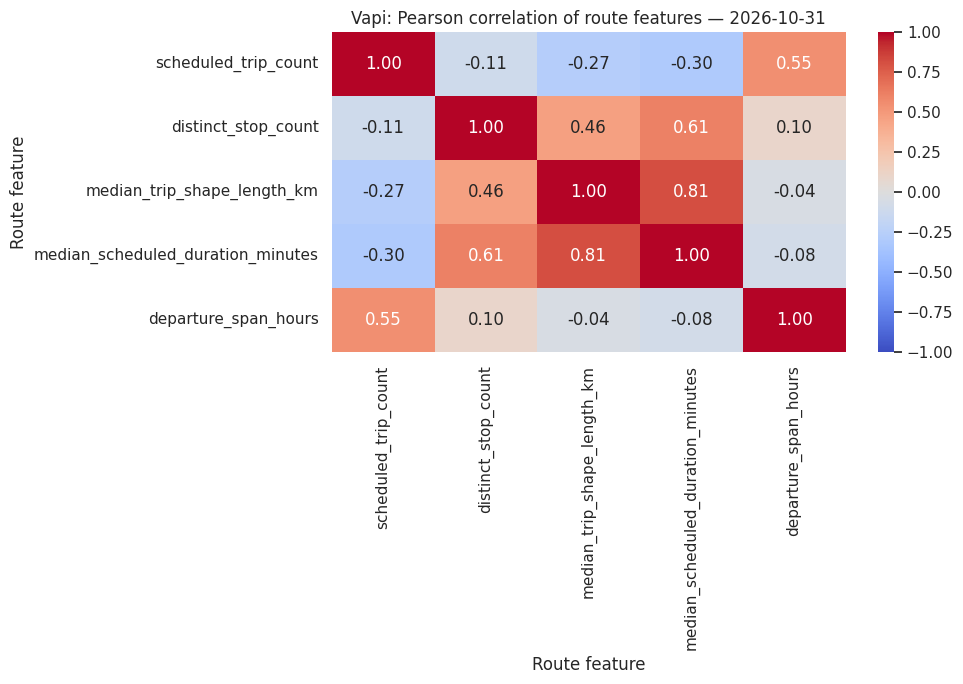


FEATURE ASSOCIATIONS


,feature_1,feature_2,pearson_r,spearman_r,paired_routes
0,scheduled_trip_count,distinct_stop_count,-0.108626,-0.207778,22
1,scheduled_trip_count,median_trip_shape_length_km,-0.268134,-0.151798,22
2,scheduled_trip_count,median_scheduled_duration_minutes,-0.304612,-0.331688,22
3,scheduled_trip_count,departure_span_hours,0.553321,0.708816,22
4,distinct_stop_count,median_trip_shape_length_km,0.462171,0.686638,22
5,distinct_stop_count,median_scheduled_duration_minutes,0.610231,0.785604,22
6,distinct_stop_count,departure_span_hours,0.095799,-0.216981,22
7,median_trip_shape_length_km,median_scheduled_duration_minutes,0.814208,0.823197,22
8,median_trip_shape_length_km,departure_span_hours,-0.044266,-0.126268,22
9,median_scheduled_duration_minutes,departure_span_hours,-0.080660,-0.144346,22


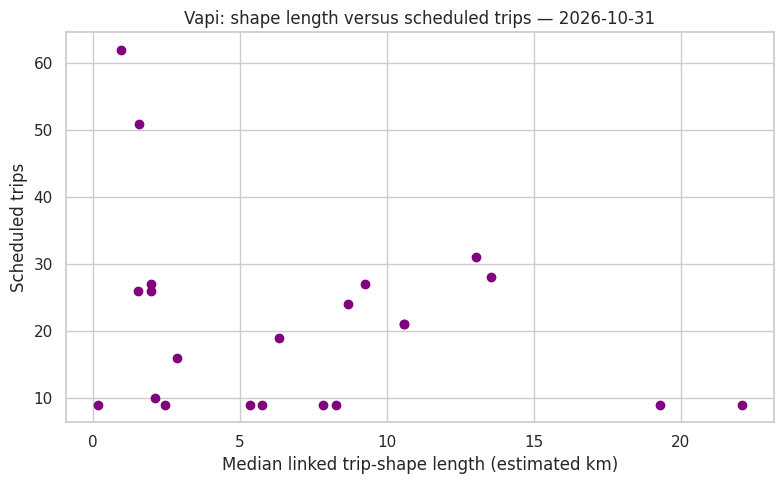


TOP SHARED-STOP PAIRS


,route_1,route_2,shared_stop_count,union_stop_count,jaccard_shared_stop_ratio
230,1889,1890,7,7,1.000000
78,1833,1834,5,5,1.000000
225,1887,1888,5,5,1.000000
140,1845,1846,4,4,1.000000
151,1845,1889,3,8,0.375000
152,1845,1890,3,8,0.375000
163,1846,1889,3,8,0.375000
164,1846,1890,3,8,0.375000
58,1831,1889,4,11,0.363636
59,1831,1890,4,11,0.363636



QUALITY FINDINGS
No issues detected in the checks performed.

MODULE 3 ANALYSIS FINISHED
Routes: 22
Trip records: 461
Charts generated: 14
Geography: Not produced: original Vapi GTFS files were not uploaded.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Also save this executed notebook:
File → Download → Download .ipynb
Name: Module3_Exploratory_Data_Analysis.ipynb


In [3]:
# ROUTERANKER — MODULE 3: EXPLORATORY DATA ANALYSIS
# Run in ONE Google Colab cell.
# Required: RouteRanker_Module2_Vapi.zip
# Optional: Original GTFS CSV ZIP for geographical visualization.

from google.colab import files
from pathlib import Path
from IPython.display import display
from itertools import combinations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import shutil
import json
import html

# ==================================================
# 1. UPLOAD FILES
# ==================================================

print("Upload the Module 2 results ZIP.")
print("Optionally select the original GTFS ZIP at the same time.")

uploaded = files.upload()

# Use a fresh run folder to avoid mixing earlier outputs.
BASE = Path("/content/RouteRanker_Module3")
BASE.mkdir(parents=True, exist_ok=True)

PROJECT = BASE / pd.Timestamp.now().strftime("%Y%m%d_%H%M%S_%f")
INPUT = PROJECT / "input"
OUTPUT = PROJECT / "results"
CHARTS = OUTPUT / "charts"
TABLES = OUTPUT / "tables"

for folder in [INPUT, OUTPUT, CHARTS, TABLES]:
    folder.mkdir(parents=True, exist_ok=True)

archive_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if not archive_names:
    raise ValueError("Please upload the Module 2 results ZIP.")

for index, name in enumerate(archive_names):
    destination = INPUT / f"archive_{index}"
    destination.mkdir()

    with zipfile.ZipFile(name) as archive:
        root = destination.resolve()

        for member in archive.infolist():
            target = (destination / member.filename).resolve()

            if target != root and root not in target.parents:
                raise ValueError("Unsafe ZIP path detected.")

        archive.extractall(destination)

def read_output(filename, required=True):
    matches = list(INPUT.rglob(filename))

    if not matches:
        if required:
            raise FileNotFoundError(
                f"{filename} was not found. "
                "Upload RouteRanker_Module2_Vapi.zip."
            )
        return None

    if len(matches) > 1:
        raise ValueError(
            f"Multiple copies of {filename} found. "
            "Upload only one Module 2 results ZIP."
        )

    return pd.read_csv(
        matches[0],
        dtype="string",
        keep_default_na=False,
        encoding="utf-8-sig"
    )

profiles_source = read_output("vapi_route_profiles.csv")
trips_source = read_output("vapi_trip_features.csv")
hourly_source = read_output("vapi_hourly_departures.csv")
patterns = read_output("vapi_stop_patterns.csv", required=False)

# ==================================================
# 2. QUALITY CHECKS AND NUMERIC TYPES
# ==================================================

quality = []
observations = []

def check(label, count, action):
    quality.append({
        "check": label,
        "affected_rows": int(count),
        "action_or_interpretation": action
    })

required = {
    "profiles": (
        profiles_source,
        ["route_id", "service_date", "scheduled_trip_count"]
    ),
    "trips": (
        trips_source,
        [
            "route_id", "trip_id", "service_date",
            "departure_seconds", "service_hour"
        ]
    ),
    "hourly": (
        hourly_source,
        [
            "route_id", "service_date",
            "service_hour", "scheduled_departures"
        ]
    )
}

for name, (df, columns) in required.items():
    absent = set(columns) - set(df.columns)

    if absent:
        raise ValueError(f"{name}: missing columns {sorted(absent)}")

    check(
        f"{name}: exact duplicate rows",
        df.duplicated().sum(),
        "Recorded; investigate duplicates before interpreting totals."
    )

    for column in df:
        check(
            f"{name}.{column}: blank cells",
            df[column].str.strip().eq("").sum(),
            "Missing values preserved; optional fields may be blank."
        )

for name, df, keys in [
    ("profiles", profiles_source, ["route_id", "service_date"]),
    ("trips", trips_source, ["trip_id", "service_date"]),
    (
        "hourly", hourly_source,
        ["route_id", "service_date", "service_hour"]
    )
]:
    duplicates = df.duplicated(keys, keep=False)
    blank_keys = df[keys].apply(
        lambda column: column.str.strip().eq("")
    ).any(axis=1)

    check(f"{name}: repeated keys", duplicates.sum(), "Must be investigated.")
    check(f"{name}: blank keys", blank_keys.sum(), "Must be investigated.")

    if duplicates.any() or blank_keys.any():
        raise ValueError(
            f"{name} has duplicate or blank keys. "
            "Resolve them before running aggregate EDA."
        )

dates = profiles_source["service_date"].unique().tolist()

if len(dates) != 1:
    raise ValueError(
        "This program analyses one service date at a time. "
        "Upload outputs for one selected date."
    )

DATE = dates[0]

if pd.isna(pd.to_datetime(DATE, format="%Y-%m-%d", errors="coerce")):
    raise ValueError("Invalid service date.")

for name, df in [
    ("trips", trips_source),
    ("hourly", hourly_source)
]:
    if set(df["service_date"]) != {DATE}:
        raise ValueError(f"{name}: service dates do not match profiles.")

numeric_features = [
    column for column in [
        "scheduled_trip_count",
        "distinct_stop_count",
        "trips_with_valid_departure",
        "first_departure_seconds",
        "last_departure_seconds",
        "median_scheduled_duration_minutes",
        "departure_span_hours",
        "trips_with_shape_distance",
        "median_trip_shape_length_km",
        "min_trip_shape_length_km",
        "max_trip_shape_length_km"
    ]
    if column in profiles_source
]

count_fields = {
    "scheduled_trip_count",
    "distinct_stop_count",
    "trips_with_valid_departure",
    "trips_with_shape_distance",
    "service_hour",
    "scheduled_departures"
}

def numeric_copy(df, columns, name):
    result = df.copy()

    for column in columns:
        source = df[column]
        blank = source.str.strip().eq("")
        values = pd.to_numeric(source, errors="coerce")

        malformed = ~blank & values.isna()
        infinite = values.notna() & ~np.isfinite(values)
        negative = values.lt(0)

        check(
            f"{name}.{column}: malformed numbers",
            malformed.sum(),
            "Excluded from numerical analysis; original values retained."
        )
        check(
            f"{name}.{column}: infinite values",
            infinite.sum(),
            "Excluded from numerical analysis."
        )
        check(
            f"{name}.{column}: negative values",
            negative.sum(),
            "Excluded because these features must be nonnegative."
        )

        invalid = malformed | infinite | negative

        if column in count_fields:
            fractional = values.notna() & values.mod(1).ne(0)
            invalid = invalid | fractional

            check(
                f"{name}.{column}: fractional counts",
                fractional.sum(),
                "Excluded; counts and hour indices must be integers."
            )

        result[column] = values.mask(invalid)

    return result

profiles = numeric_copy(
    profiles_source, numeric_features, "profiles"
)

trips = numeric_copy(
    trips_source,
    ["departure_seconds", "service_hour"],
    "trips"
)

hourly = numeric_copy(
    hourly_source,
    ["service_hour", "scheduled_departures"],
    "hourly"
)

profile_keys = set(
    zip(profiles["route_id"], profiles["service_date"])
)

for name, df in [("trips", trips), ("hourly", hourly)]:
    unmatched = [
        (route, date) not in profile_keys
        for route, date in zip(df["route_id"], df["service_date"])
    ]
    check(
        f"{name}: unknown route/date",
        sum(unmatched),
        "References must exist in route profiles."
    )

    if any(unmatched):
        raise ValueError(f"{name}: unknown route/date references.")

# Reconcile route trip counts.
actual_counts = trips.groupby("route_id")["trip_id"].nunique()
reported_counts = profiles.set_index("route_id")["scheduled_trip_count"]

actual_counts = actual_counts.reindex(reported_counts.index, fill_value=0)

mismatched = (
    reported_counts.isna()
    | reported_counts.ne(actual_counts)
)

check(
    "Route trip counts disagree with trip table",
    mismatched.sum(),
    "Compare per-route scheduled count against distinct trip records."
)

# Check time-feature consistency.
expected_hour = np.floor(trips["departure_seconds"] / 3600)

bad_hour = (
    trips["departure_seconds"].notna()
    & (
        trips["service_hour"].isna()
        | trips["service_hour"].ne(expected_hour)
    )
)

check(
    "Trips: service hour inconsistent with departure seconds",
    bad_hour.sum(),
    "Derived service hour is used for the EDA charts."
)

trips["eda_service_hour"] = expected_hour
trips["eda_clock_hour"] = expected_hour % 24

def period(hour):
    if pd.isna(hour):
        return pd.NA
    if 5 <= hour < 12:
        return "Morning"
    if 12 <= hour < 17:
        return "Afternoon"
    if 17 <= hour < 21:
        return "Evening"
    return "Night"

trips["eda_time_period"] = trips["eda_clock_hour"].apply(period)

if "time_period" in trips:
    mismatch = (
        trips["eda_time_period"].notna()
        & trips["time_period"].ne(trips["eda_time_period"])
    )

    check(
        "Trips: time-period label mismatch",
        mismatch.sum(),
        "EDA uses categories derived from departure seconds."
    )

valid_trips = trips.dropna(subset=["eda_service_hour"]).copy()

derived_hourly = (
    valid_trips.groupby(["route_id", "eda_service_hour"])
    .size()
    .rename("derived_departures")
    .reset_index()
    .rename(columns={"eda_service_hour": "service_hour"})
)

usable_hourly = hourly.dropna(
    subset=["service_hour", "scheduled_departures"]
)

reconciliation = derived_hourly.merge(
    usable_hourly[[
        "route_id", "service_hour", "scheduled_departures"
    ]],
    on=["route_id", "service_hour"],
    how="outer",
    validate="one_to_one"
)

hourly_mismatch = (
    reconciliation["derived_departures"].fillna(0)
    != reconciliation["scheduled_departures"].fillna(0)
)

check(
    "Hourly table differs from trip-derived counts",
    hourly_mismatch.sum(),
    "Charts use trip-derived counts; differences remain documented."
)

reconciliation.to_csv(
    TABLES / "hourly_reconciliation.csv", index=False
)

# ==================================================
# 3. INSPECTION AND DESCRIPTIVE STATISTICS
# ==================================================

print("\nDATASET SHAPE:", profiles.shape)
print("SERVICE DATE:", DATE)

print("\nDATA TYPES")
profiles.info()

print("\nFIRST FIVE ROUTES")
display(profiles.head())

print("\nLAST FIVE ROUTES")
display(profiles.tail())

print("\nMISSING NUMERICAL VALUES AFTER VALIDATION")
display(profiles[numeric_features].isnull().sum())

statistics = profiles[numeric_features].describe().T
statistics.to_csv(TABLES / "descriptive_statistics.csv")

print("\nDESCRIPTIVE STATISTICS")
display(statistics)

# Route IDs stay as text, even when they contain digits.
profiles["route_label"] = "ID " + profiles["route_id"]

sns.set_theme(style="whitegrid")
captions = []

def save_chart(filename, title, explanation):
    plt.tight_layout()
    plt.savefig(CHARTS / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

    captions.append({
        "chart": filename,
        "title": title,
        "interpretation": explanation
    })

# ==================================================
# 4. FEATURE DISTRIBUTIONS
# ==================================================

distribution_features = [
    column for column in [
        "scheduled_trip_count",
        "distinct_stop_count",
        "median_trip_shape_length_km",
        "departure_span_hours"
    ]
    if column in profiles
]

for column in distribution_features:
    values = profiles[column].dropna()

    if values.empty:
        continue

    title = f"Vapi: distribution of {column} — {DATE}"
    plt.figure(figsize=(9, 4))
    plt.hist(
        values,
        bins=min(10, max(1, values.nunique())),
        color="steelblue",
        edgecolor="white"
    )
    plt.title(title)
    plt.xlabel(column.replace("_", " "))
    plt.ylabel("Number of routes")

    explanation = (
        f"{len(values)} routes have usable values. "
        f"Minimum={values.min():.2f}, maximum={values.max():.2f}, "
        f"mean={values.mean():.2f}, median={values.median():.2f}. "
        "Differences describe the recorded route features."
    )

    save_chart(f"hist_{column}.png", title, explanation)

    title = f"Vapi: spread of {column} — {DATE}"
    plt.figure(figsize=(9, 3))
    plt.boxplot(values, vert=False)
    plt.title(title)
    plt.xlabel(column.replace("_", " "))
    plt.yticks([1], ["Routes"])

    save_chart(
        f"box_{column}.png",
        title,
        "Points beyond the box-plot whiskers are candidates for review, "
        "not automatically invalid observations."
    )

# ==================================================
# 5. HOURLY AND TIME-PERIOD PATTERNS
# ==================================================

if valid_trips.empty:
    raise ValueError("No valid departure times available for time analysis.")

observed_hourly = (
    valid_trips.groupby("eda_service_hour")
    .size()
)

last_hour = max(23, int(observed_hourly.index.max()))

# Omitted hours get zero recorded starts, not proof of actual no-service.
hour_counts = observed_hourly.reindex(
    range(last_hour + 1), fill_value=0
)
hour_counts.index.name = "service_hour"
hour_counts.name = "scheduled_trip_starts"

hour_counts.to_csv(TABLES / "hourly_service_summary.csv")

peak_hours = hour_counts[
    hour_counts.eq(hour_counts.max())
].index.tolist()

zero_hours = hour_counts[hour_counts.eq(0)].index.tolist()

positive_counts = hour_counts[hour_counts.gt(0)]
lowest_positive_hours = positive_counts[
    positive_counts.eq(positive_counts.min())
].index.tolist()

title = f"Vapi: recorded scheduled trip starts by service hour — {DATE}"
plt.figure(figsize=(12, 4))
plt.bar(hour_counts.index, hour_counts.values, color="teal")
plt.title(title)
plt.xlabel("Service-day hour (24+ means after midnight)")
plt.ylabel("Scheduled trip starts")
plt.xticks(hour_counts.index, rotation=90)

hour_explanation = (
    f"Peak hour(s): {peak_hours}, with {int(hour_counts.max())} starts each. "
    f"Lowest nonzero hour(s): {lowest_positive_hours}, "
    f"with {int(positive_counts.min())} starts each. "
    f"Hours with no recorded starts: {zero_hours}. "
    "Zeros describe this dataset; they do not establish source completeness."
)

save_chart("hourly_departures.png", title, hour_explanation)
observations.append(hour_explanation)

period_order = ["Morning", "Afternoon", "Evening", "Night"]

period_counts = (
    valid_trips.groupby("eda_time_period")
    .size()
    .reindex(period_order, fill_value=0)
)

period_counts.rename("scheduled_trip_starts").to_csv(
    TABLES / "time_period_summary.csv"
)

title = f"Vapi: scheduled trip starts by time period — {DATE}"
plt.figure(figsize=(8, 4))
plt.bar(period_counts.index, period_counts.values, color="darkorange")
plt.title(title)
plt.xlabel("Time period")
plt.ylabel("Scheduled trip starts")

save_chart(
    "time_period_departures.png",
    title,
    f"Recorded starts: {period_counts.to_dict()}. "
    "Morning=05–11, Afternoon=12–16, Evening=17–20, "
    "Night=21–04 by clock hour. Period lengths differ, "
    "so raw totals are not directly comparable hourly rates."
)

# ==================================================
# 6. ROUTE COMPARISONS
# ==================================================

route_periods = pd.crosstab(
    valid_trips["route_id"],
    valid_trips["eda_time_period"]
).reindex(columns=period_order, fill_value=0)

route_periods.columns = [
    f"{column.lower()}_trip_starts"
    for column in route_periods.columns
]

comparison = profiles.merge(
    route_periods,
    left_on="route_id",
    right_index=True,
    how="left",
    validate="one_to_one"
)

for column in route_periods.columns:
    comparison[column] = comparison[column].fillna(0).astype(int)

comparison = comparison.sort_values(
    "scheduled_trip_count", ascending=False
)

comparison.to_csv(TABLES / "route_comparison.csv", index=False)

print("\nROUTE COMPARISON")
display(comparison)

ordered = profiles.sort_values("scheduled_trip_count")

title = f"Vapi: scheduled trips per route — {DATE}"
plt.figure(figsize=(10, max(5, len(ordered) * 0.27)))
plt.barh(
    ordered["route_label"],
    ordered["scheduled_trip_count"],
    color="royalblue"
)
plt.title(title)
plt.xlabel("Scheduled trips on selected date")
plt.ylabel("Route identifier")

usable_counts = profiles.dropna(subset=["scheduled_trip_count"])

highest = usable_counts.loc[
    usable_counts["scheduled_trip_count"].eq(
        usable_counts["scheduled_trip_count"].max()
    ),
    "route_id"
].tolist()

lowest = usable_counts.loc[
    usable_counts["scheduled_trip_count"].eq(
        usable_counts["scheduled_trip_count"].min()
    ),
    "route_id"
].tolist()

route_explanation = (
    f"Highest-count route(s): {highest}; lowest-count route(s): {lowest}. "
    "A lower scheduled trip count alone does not prove underutilisation."
)

save_chart("route_trip_comparison.png", title, route_explanation)
observations.append(route_explanation)

if "distinct_stop_count" in profiles:
    stop_order = profiles.sort_values("distinct_stop_count")

    title = f"Vapi: distinct stops per route — {DATE}"
    plt.figure(figsize=(10, max(5, len(stop_order) * 0.27)))
    plt.barh(
        stop_order["route_label"],
        stop_order["distinct_stop_count"],
        color="seagreen"
    )
    plt.title(title)
    plt.xlabel("Distinct recorded stops")
    plt.ylabel("Route identifier")

    valid_stops = profiles.dropna(subset=["distinct_stop_count"])

    if not valid_stops.empty:
        maximum = valid_stops["distinct_stop_count"].max()
        most_stops = valid_stops.loc[
            valid_stops["distinct_stop_count"].eq(maximum),
            "route_id"
        ].tolist()

        explanation = (
            f"Route(s) {most_stops} have the largest recorded stop count: "
            f"{int(maximum)}. Completeness of recorded stop lists "
            "requires separate verification."
        )
    else:
        explanation = "No usable stop counts were available."

    save_chart("route_stop_comparison.png", title, explanation)
    observations.append(explanation)

# ==================================================
# 7. CORRELATION ANALYSIS
# ==================================================

correlation_candidates = [
    column for column in [
        "scheduled_trip_count",
        "distinct_stop_count",
        "median_trip_shape_length_km",
        "median_scheduled_duration_minutes",
        "departure_span_hours"
    ]
    if column in profiles
]

# Remove constant and insufficiently populated features.
correlation_columns = [
    column for column in correlation_candidates
    if profiles[column].notna().sum() >= 3
    and profiles[column].nunique(dropna=True) > 1
]

if len(correlation_columns) >= 2:
    numerical = profiles[correlation_columns]

    pearson = numerical.corr(method="pearson", min_periods=3)
    spearman = numerical.corr(method="spearman", min_periods=3)

    available = numerical.notna().astype(int)
    pair_counts = available.T.dot(available)

    pearson.to_csv(TABLES / "pearson_correlation.csv")
    spearman.to_csv(TABLES / "spearman_correlation.csv")
    pair_counts.to_csv(TABLES / "correlation_sample_sizes.csv")

    title = f"Vapi: Pearson correlation of route features — {DATE}"
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        pearson,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )
    plt.title(title)
    plt.xlabel("Route feature")
    plt.ylabel("Route feature")

    save_chart(
        "correlation_heatmap.png",
        title,
        "Positive values indicate features tend to increase together; "
        "negative values indicate opposite linear tendencies. "
        "Missing values use pairwise available observations. "
        "See sample-size table. Associations are descriptive, "
        "sensitive to outliers, and do not establish causation. "
        "Route IDs are excluded."
    )

    association_rows = []

    for first, second in combinations(correlation_columns, 2):
        association_rows.append({
            "feature_1": first,
            "feature_2": second,
            "pearson_r": pearson.loc[first, second],
            "spearman_r": spearman.loc[first, second],
            "paired_routes": pair_counts.loc[first, second]
        })

    associations = pd.DataFrame(association_rows)
    associations.to_csv(
        TABLES / "feature_associations.csv", index=False
    )

    print("\nFEATURE ASSOCIATIONS")
    display(associations)

    if "median_trip_shape_length_km" in correlation_columns:
        title = f"Vapi: shape length versus scheduled trips — {DATE}"
        plt.figure(figsize=(8, 5))
        plt.scatter(
            profiles["median_trip_shape_length_km"],
            profiles["scheduled_trip_count"],
            color="purple"
        )
        plt.title(title)
        plt.xlabel("Median linked trip-shape length (estimated km)")
        plt.ylabel("Scheduled trips")

        save_chart(
            "length_vs_trips.png",
            title,
            "Each point represents one route. Shape length may be "
            "incomplete; investigate very short geometry and "
            "outliers before interpreting the relationship."
        )
else:
    observations.append(
        "Correlation skipped: fewer than two usable varying numerical features."
    )

# ==================================================
# 8. OUTLIER AND GEOMETRY-COVERAGE REVIEW
# ==================================================

outlier_rows = []

for column in distribution_features:
    values = profiles[column].dropna()

    if len(values) < 4:
        continue

    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1

    if iqr == 0:
        observations.append(
            f"IQR outlier screening skipped for {column}: zero IQR."
        )
        continue

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    candidates = profiles[
        profiles[column].lt(lower) | profiles[column].gt(upper)
    ]

    for _, row in candidates.iterrows():
        outlier_rows.append({
            "route_id": row["route_id"],
            "feature": column,
            "value": row[column],
            "lower_fence": lower,
            "upper_fence": upper,
            "action": "Retained; investigate source and context."
        })

outliers = pd.DataFrame(
    outlier_rows,
    columns=[
        "route_id", "feature", "value",
        "lower_fence", "upper_fence", "action"
    ]
)

outliers.to_csv(TABLES / "outlier_candidates.csv", index=False)

if "median_trip_shape_length_km" in profiles:
    short_shapes = profiles[
        profiles["median_trip_shape_length_km"].lt(1)
    ]

    short_shapes.to_csv(
        TABLES / "shape_estimates_below_1km.csv", index=False
    )

    observations.append(
        f"{len(short_shapes)} route(s) have median shape estimates below "
        "1 km. This is a review threshold, not an invalidity rule."
    )

if {
    "trips_with_shape_distance", "scheduled_trip_count"
}.issubset(profiles.columns):
    coverage = profiles[[
        "route_id",
        "scheduled_trip_count",
        "trips_with_shape_distance"
    ]].copy()

    coverage["shape_coverage_fraction"] = (
        coverage["trips_with_shape_distance"]
        / coverage["scheduled_trip_count"].replace(0, np.nan)
    )

    coverage.to_csv(TABLES / "shape_coverage.csv", index=False)

    check(
        "Routes with partial shape coverage",
        (
            coverage["scheduled_trip_count"].gt(0)
            & coverage["trips_with_shape_distance"].lt(
                coverage["scheduled_trip_count"]
            )
        ).sum(),
        "Distance summaries may represent only some trips."
    )

# ==================================================
# 9. SHARED-STOP OVERLAP CANDIDATES
# ==================================================

overlap_rows = []

if patterns is not None and "pattern_id" in trips:
    pattern_stops = {}

    for _, row in patterns.iterrows():
        try:
            values = json.loads(row["ordered_stop_ids"])

            if not isinstance(values, list):
                raise ValueError("Expected a list.")

            pattern_stops[row["pattern_id"]] = {
                str(value) for value in values
            }
        except Exception:
            check(
                "Invalid serialized stop pattern",
                1,
                "Pattern omitted from shared-stop calculation."
            )

    route_stops = {}
    complete_routes = {}

    for route_id, group in trips.groupby("route_id"):
        ids = set(group["pattern_id"])
        complete_routes[route_id] = (
            len(ids) > 0
            and all(pattern in pattern_stops for pattern in ids)
        )

        route_stops[route_id] = set().union(
            *(pattern_stops.get(pattern, set()) for pattern in ids)
        )

    check(
        "Routes with incomplete stop-pattern coverage",
        sum(not value for value in complete_routes.values()),
        "Excluded from pairwise shared-stop comparison."
    )

    eligible = [
        route for route in route_stops
        if complete_routes[route] and route_stops[route]
    ]

    for first, second in combinations(sorted(eligible), 2):
        a, b = route_stops[first], route_stops[second]
        shared = a & b

        overlap_rows.append({
            "route_1": first,
            "route_2": second,
            "shared_stop_count": len(shared),
            "union_stop_count": len(a | b),
            "jaccard_shared_stop_ratio": len(shared) / len(a | b)
        })

    overlaps = pd.DataFrame(overlap_rows)

    if not overlaps.empty:
        overlaps = overlaps.sort_values(
            ["jaccard_shared_stop_ratio", "shared_stop_count"],
            ascending=False
        )

        overlaps.to_csv(
            TABLES / "shared_stop_overlap_candidates.csv",
            index=False
        )

        print("\nTOP SHARED-STOP PAIRS")
        display(overlaps.head(10))

        observations.append(
            "Shared-stop overlap uses intersection/union of recorded "
            "stop IDs. It ignores direction, order and nearby stops "
            "with different IDs. It does not establish redundancy."
        )
else:
    observations.append(
        "Shared-stop analysis unavailable: stop-pattern outputs missing."
    )

# ==================================================
# 10. OPTIONAL GEOGRAPHICAL MAP
# ==================================================

geo_status = "Not produced: original Vapi GTFS files were not uploaded."

vapi_folders = sorted({
    path.parent
    for path in INPUT.rglob("stops.csv")
    if path.parent.name == "Vapi_GTFS"
})

if len(vapi_folders) == 1:
    raw_folder = vapi_folders[0]

    try:
        import folium

        raw_stops = pd.read_csv(
            raw_folder / "stops.csv",
            dtype="string",
            keep_default_na=False
        )

        raw_stops["lat"] = pd.to_numeric(
            raw_stops["stop_lat"], errors="coerce"
        )
        raw_stops["lon"] = pd.to_numeric(
            raw_stops["stop_lon"], errors="coerce"
        )

        valid_geo = (
            raw_stops["lat"].between(-90, 90)
            & raw_stops["lon"].between(-180, 180)
        )

        check(
            "Raw stops: unusable coordinates",
            (~valid_geo).sum(),
            "Excluded from map only; source records unchanged."
        )

        mapped = raw_stops[valid_geo]

        if mapped.empty:
            geo_status = "No usable stop coordinates available."
        else:
            route_map = folium.Map(
                location=[
                    mapped["lat"].median(),
                    mapped["lon"].median()
                ],
                zoom_start=12
            )

            stop_layer = folium.FeatureGroup(
                name="Recorded Vapi stops"
            )

            for _, row in mapped.iterrows():
                name = row.get("stop_name", row["stop_id"])

                folium.CircleMarker(
                    location=[row["lat"], row["lon"]],
                    radius=4,
                    color="navy",
                    fill=True,
                    fill_opacity=0.7,
                    popup=html.escape(str(name))
                ).add_to(stop_layer)

            stop_layer.add_to(route_map)

            shape_path = raw_folder / "shapes.csv"
            plotted_shapes = 0

            if shape_path.exists() and "shape_id" in trips:
                raw_shapes = pd.read_csv(
                    shape_path,
                    dtype="string",
                    keep_default_na=False
                )

                linked_shapes = raw_shapes[
                    raw_shapes["shape_id"].isin(trips["shape_id"])
                ]

                shape_layer = folium.FeatureGroup(
                    name="Linked active-trip shapes"
                )

                for shape_id, group in linked_shapes.groupby("shape_id"):
                    group = group.copy()

                    for column in [
                        "shape_pt_lat",
                        "shape_pt_lon",
                        "shape_pt_sequence"
                    ]:
                        group[column] = pd.to_numeric(
                            group[column], errors="coerce"
                        )

                    seq = group["shape_pt_sequence"]
                    valid = (
                        group["shape_pt_lat"].between(-90, 90)
                        & group["shape_pt_lon"].between(-180, 180)
                        & seq.notna()
                        & seq.ge(0)
                        & seq.mod(1).eq(0)
                    )

                    if (
                        len(group) < 2
                        or not valid.all()
                        or seq.duplicated().any()
                    ):
                        check(
                            "Shape groups skipped on map",
                            1,
                            "Entire invalid shape omitted."
                        )
                        continue

                    group = group.sort_values("shape_pt_sequence")

                    folium.PolyLine(
                        group[[
                            "shape_pt_lat", "shape_pt_lon"
                        ]].values.tolist(),
                        weight=3,
                        opacity=0.55,
                        tooltip=html.escape(str(shape_id))
                    ).add_to(shape_layer)

                    plotted_shapes += 1

                shape_layer.add_to(route_map)

            folium.LayerControl().add_to(route_map)

            route_map.save(str(OUTPUT / "vapi_geographical_map.html"))

            display(route_map)

            geo_status = (
                f"Mapped {len(mapped)} recorded stops and "
                f"{plotted_shapes} linked shapes. "
                "All source stops are shown; not all need be active "
                "on the selected date. Map is not a passenger-density "
                "or quantified segment-overlap map. Basemap requires internet."
            )

    except ImportError:
        geo_status = (
            "Folium is unavailable. Install it using "
            "'%pip install folium' and rerun for the map."
        )

observations.append(geo_status)

# ==================================================
# 11. SAVE REPORTS AND LIMITATIONS
# ==================================================

quality_df = pd.DataFrame(quality)
quality_df.to_csv(TABLES / "data_quality_summary.csv", index=False)

findings = quality_df[quality_df["affected_rows"] > 0]

limitations = [
    "Scope: Vapi feed and one service date only.",
    f"Service date: {DATE}.",
    "Weekday/weekend comparison cannot be established from one date.",
    "Trip starts are counted once at each trip's first recorded stop.",
    "Hours above 23 remain separate service-day hours.",
    "Time periods use clock hours; their lengths differ.",
    "Missing or invalid numeric measurements are excluded from "
    "relevant summaries; original input files remain unchanged.",
    "Zero recorded starts do not establish that the source schedule is complete.",
    "Shape lengths estimate linked geometry and may be incomplete.",
    "Departure span describes first-to-last trip starts, not continuous service.",
    "Correlation uses available route pairs; sample sizes are saved.",
    "The small route sample and source issues can affect correlations.",
    "Outliers are retained; no automatic deletion or imputation is performed.",
    "Shared stops do not establish shared geographical segments or redundancy.",
    "Ridership, occupancy, costs, actual travel times and fleet information "
    "are needed for stronger operational conclusions.",
    "Scheduled trip counts cannot establish overcrowding or underutilisation."
]

(OUTPUT / "findings_and_limitations.md").write_text(
    "# Findings and limitations\n\n"
    + "\n".join(f"- {item}" for item in observations)
    + "\n\n## Limitations\n\n"
    + "\n".join(f"- {item}" for item in limitations),
    encoding="utf-8"
)

report = [
    "# RouteRanker Module 3 — Vapi EDA",
    "",
    f"Service date: {DATE}",
    f"Route profiles: {len(profiles)}",
    f"Trip records: {len(trips)}",
    f"Trips with usable departure times: {len(valid_trips)}",
    "",
    "## Main observations",
    ""
]

report.extend(f"- {item}" for item in observations)

report.extend([
    "",
    "## Data quality",
    "",
    f"Checks with findings: {len(findings)}.",
    "See tables/data_quality_summary.csv for counts and decisions.",
    "No automatic correction of raw data was performed.",
    "",
    "## Chart interpretations",
    ""
])

for caption in captions:
    report.extend([
        f"### {caption['title']}",
        f"File: charts/{caption['chart']}",
        caption["interpretation"],
        ""
    ])

report.extend([
    "## Further investigation",
    "",
    "Verify short route geometry, sparse stop patterns, and any "
    "outliers against original source information.",
    "Review shared-stop pairs in their direction and operating context.",
    "No operational inefficiency is established by this EDA."
])

(OUTPUT / "exploratory_analysis_report.md").write_text(
    "\n".join(report),
    encoding="utf-8"
)

pd.DataFrame(captions).to_csv(
    TABLES / "chart_interpretations.csv", index=False
)

print("\nQUALITY FINDINGS")
if findings.empty:
    print("No issues detected in the checks performed.")
else:
    display(findings)

print("\nMODULE 3 ANALYSIS FINISHED")
print("Routes:", len(profiles))
print("Trip records:", len(trips))
print("Charts generated:", len(captions))
print("Geography:", geo_status)

archive_path = shutil.make_archive(
    str(PROJECT / "RouteRanker_Module3_Vapi"),
    "zip",
    root_dir=str(OUTPUT)
)

files.download(archive_path)

print("\nAlso save this executed notebook:")
print("File → Download → Download .ipynb")
print("Name: Module3_Exploratory_Data_Analysis.ipynb")